# Análisis exploratorio de datos(series de tiempo) 

Este notebook contiene el análisis exploratorio de los datasets de series de tiempo proporcionados.
El flujo de trabajo sigue esta secuencia:

a) Carga, revisión de tipos de datos y estadísticas descriptivas.

b) Visualización de distribuciones (boxplots) y resampling temporal (mensual y anual).

c) Análisis de correlación: matriz de Pearson, ajustes lineales y visualización conjunta de las 5 series.

Objetivo: Identificar correlaciones entre las variables y extraer patrones relevantes de los datos que fundamenten las decisiones de modelado posteriores.

Instalación de entorno (para no tener problemas de compatibilidad o ubicación).

In [1]:
import sys
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'pandas', 'matplotlib','seaborn','ipywidgets'])

print("Instalación en el entorno correcto.")


Instalación en el entorno correcto.


Importación de librerías

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
from pathlib import Path

Carga de datos

In [ ]:
df_prueba = pd.read_csv(Path("..") / "Datos" / "historico_equipos.csv", index_col=0, parse_dates=True)

In [4]:
df = pd.read_csv(Path("..") / "Datos" / "historico_equipos.csv", index_col=0, parse_dates=True)
df_X = pd.read_csv(Path("..") / "Datos" / "X.csv",index_col=0, parse_dates=True)
df_Y = pd.read_csv(Path("..") / "Datos" / "Y.csv")
df_Z = pd.read_csv(Path("..") / "Datos" / "Z.csv",index_col=1, parse_dates=True)

Aquí encontramos que tenemos el mismo tipo de datos con las mismas dimensiones.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3530 entries, 2010-01-04 to 2023-08-31
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Price_X        3530 non-null   float64
 1   Price_Y        3530 non-null   float64
 2   Price_Z        3530 non-null   float64
 3   Price_Equipo1  3530 non-null   float64
 4   Price_Equipo2  3530 non-null   float64
dtypes: float64(5)
memory usage: 165.5 KB


Aquí encontramos que tenemos distintos tipos y formato de datos con distintas dimensiones.

In [6]:
print(df_X.info())
print(df_Y.info())
print(df_Z.info())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9144 entries, 2024-04-04 to 1988-06-27
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Price   9144 non-null   float64
dtypes: float64(1)
memory usage: 142.9 KB
None
<class 'pandas.core.frame.DataFrame'>
Index: 4485 entries, 12/9/2023;547 to 11/7/2006;555
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Date;Price  2464 non-null   float64
dtypes: float64(1)
memory usage: 70.1+ KB
None
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3565 entries, 2010-01-01 to 2023-08-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Price   3565 non-null   float64
dtypes: float64(1)
memory usage: 55.7 KB
None


Encontramos 5 características: Price_X, Price_Y, Price_Z, Price_Equipo1 y Price_equipo2, nuestras variables objetivos son las últimas 2, desde el cargado de datos la fecha se usa como identificador.

In [7]:
df.head()

,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2010-01-04,80.12,527.5,2225.25,434.73,931.73
2010-01-05,80.59,527.5,2246.50,449.97,968.56
2010-01-06,81.89,527.5,2302.50,444.48,960.51
2010-01-07,81.51,527.5,2306.50,440.90,960.14
2010-01-08,81.37,552.5,2261.25,448.82,949.55


Exploraración de estadísticas descriptivas de los datos media, desviación estándar, máximos, minimos y cuartiles.

In [8]:
df.describe()

,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
count,3530.000000,3530.000000,3530.000000,3530.000000,3530.000000
mean,78.091014,555.527108,2037.432073,460.036901,889.980408
std,25.186945,138.489003,373.140448,113.681273,170.042689
min,19.330000,257.500000,1421.500000,208.340000,566.000000
25%,57.052500,482.500000,1767.250000,398.227500,777.702500
50%,75.400000,541.625000,1974.750000,451.250000,869.785000
75%,104.582500,620.000000,2235.937500,515.607500,979.122500
max,127.980000,1062.370000,3984.000000,855.320000,1703.960000


Visualización de las estádisticas descriptivas.

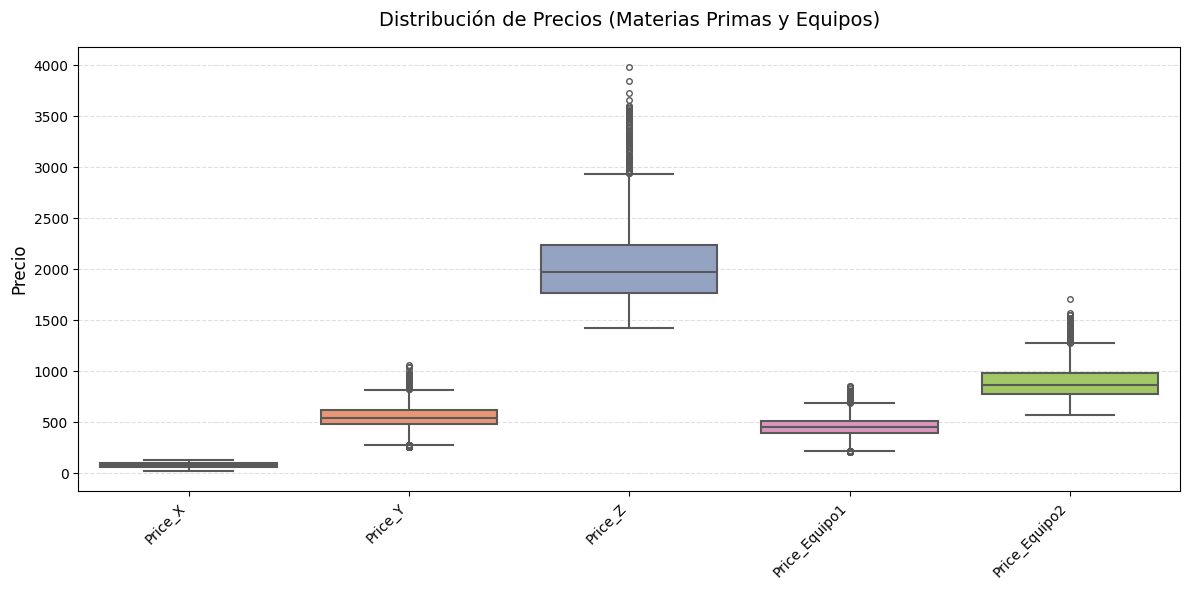

In [9]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, palette='Set2', linewidth=1.5, fliersize=4)

plt.title('Distribución de Precios (Materias Primas y Equipos)', fontsize=14, pad=15)
plt.ylabel('Precio', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

Aquí observamos que Price_Z es la caraterística con mayores outlier* Tener cuidado como se trata. Para tener una mejor visualización se recomienda una normalización o estandarización de los datos. Observamos que 4 de las 5 características tienen una tendencia a la izquierda (cola hacia la derecha).

Se hace resampling tomando mes y año por si se desea hacer un análisis más general, tomando la media como referenia, aquí se podría crear diagrams de velas japonesas.

In [10]:
df_mes=df.resample('m').mean()
df_mes

,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2010-01-31,77.013000,547.000000,2234.325000,451.818000,945.189500
2010-02-28,74.790000,538.000000,2048.575000,444.143500,886.575000
2010-03-31,79.931304,606.630435,2204.130435,501.005217,965.705652
2010-04-30,85.753810,682.976190,2313.083333,562.120476,1025.756667
2010-05-31,76.997619,679.642857,2048.666667,558.783333,932.173333
...,...,...,...,...,...
2023-04-30,83.368947,603.885789,2336.763158,503.402105,1009.561053
2023-05-31,75.694783,550.593913,2271.586957,457.468696,964.018261
2023-06-30,74.978636,541.775909,2180.738636,449.975909,931.185455


In [11]:
df_año=df.resample('Y').mean()
df_año

,Price_X,Price_Y,Price_Z,Price_Equipo1,Price_Equipo2
Date,,,,,
2010-12-31,80.339498,614.247104,2174.144788,507.227259,955.118649
2011-12-31,110.914109,684.864341,2398.605620,570.365969,1063.924845
2012-12-31,111.675465,584.602713,2017.403101,489.508876,903.901667
2013-12-31,108.704767,543.633721,1844.655039,456.359496,831.646512
2014-12-31,99.494093,502.548263,1866.771109,422.172548,823.085174
2015-12-31,53.598217,330.203488,1661.196705,275.041008,681.564767
2016-12-31,45.131822,374.263566,1604.436047,308.309070,674.181938
2017-12-31,54.745620,507.514264,1968.134690,416.931705,843.468256
2018-12-31,71.692713,565.403450,2109.982558,466.990581,915.853295


### Visualización de datos

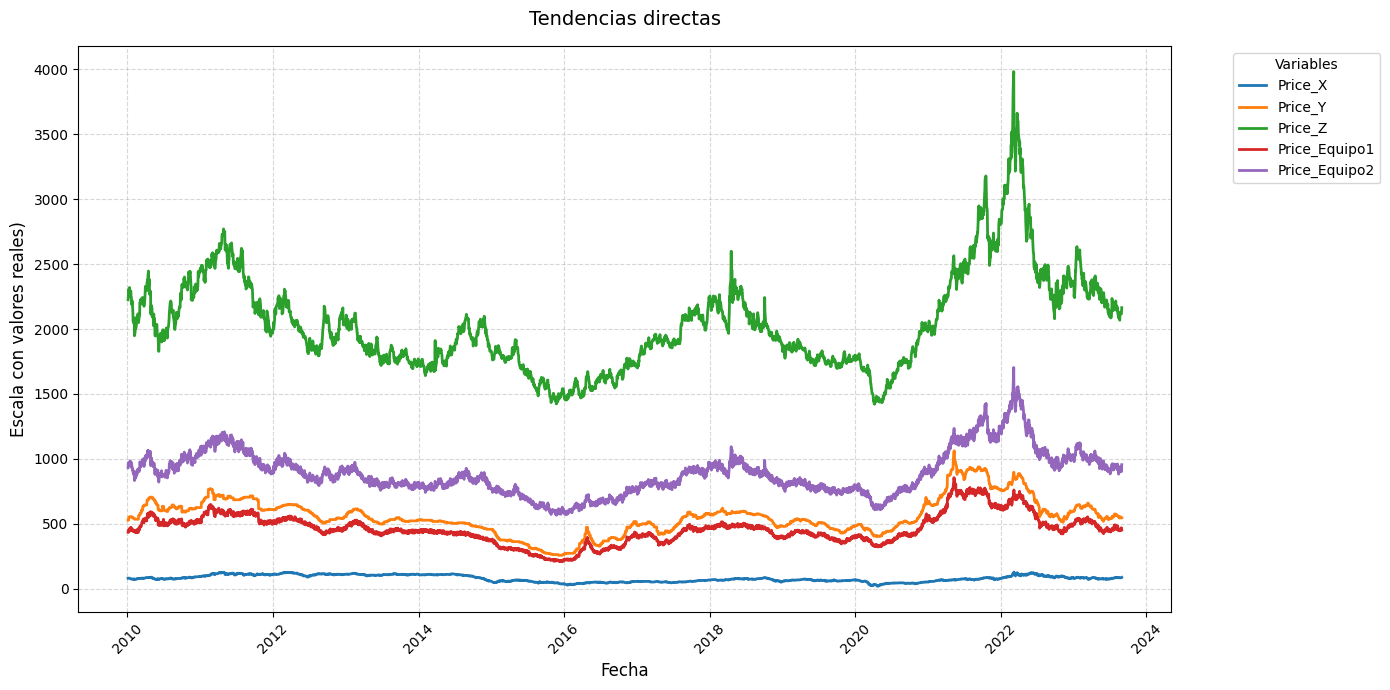

In [12]:
plt.figure(figsize=(14, 7))

sns.lineplot(data=df, dashes=False, linewidth=2, palette='tab10')

plt.title('Tendencias directas', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Escala con valores reales)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Variables', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

En la gráfica anterior, visualmente se observa una tendencia similar entre las variables Price_Z y Price_Equipo2, así como entre Price_Y con Price_Equipo1. Por el contrario, Price_X (Linea zul) no se parecia ninguna tendencia clara con las variables objetivo. 

Para comprobar estas observaciones, se sugieren validarse estaditicamente, por ejemplo, usando la matriz de correlación de Pearson. Tomaremos como referencia que una correlación fuerte está entre 0.7 y 0.9. Sin embargo, es fundamental recordar que que correlación no implica causalidad, por lo tanto, se requiere complementar este análisis junto con expertos en la materia para tener mayos claridad. 

Nota sobre el contexto: En la descripción del problema no se especifica qué representan exactamente X, Y, Z ni los equipos. Sin embargo, para contextualizar el análisis, podríamos usar como ejemplo ilustrativo un escenario de proyectos de construcción: donde X, Y y Z serían insumos o materias primas (ej. cemento, acero, combustible) y los equipos serían el producto o maquinaria final (ej. excavadoras, grúas). Esta hipótesis no altera el rigor matemático del modelo, pero nos ayuda a aterrizar la lógica de negocio detrás de los datos.

Tendencias normalizadas para hacer una comparación directa

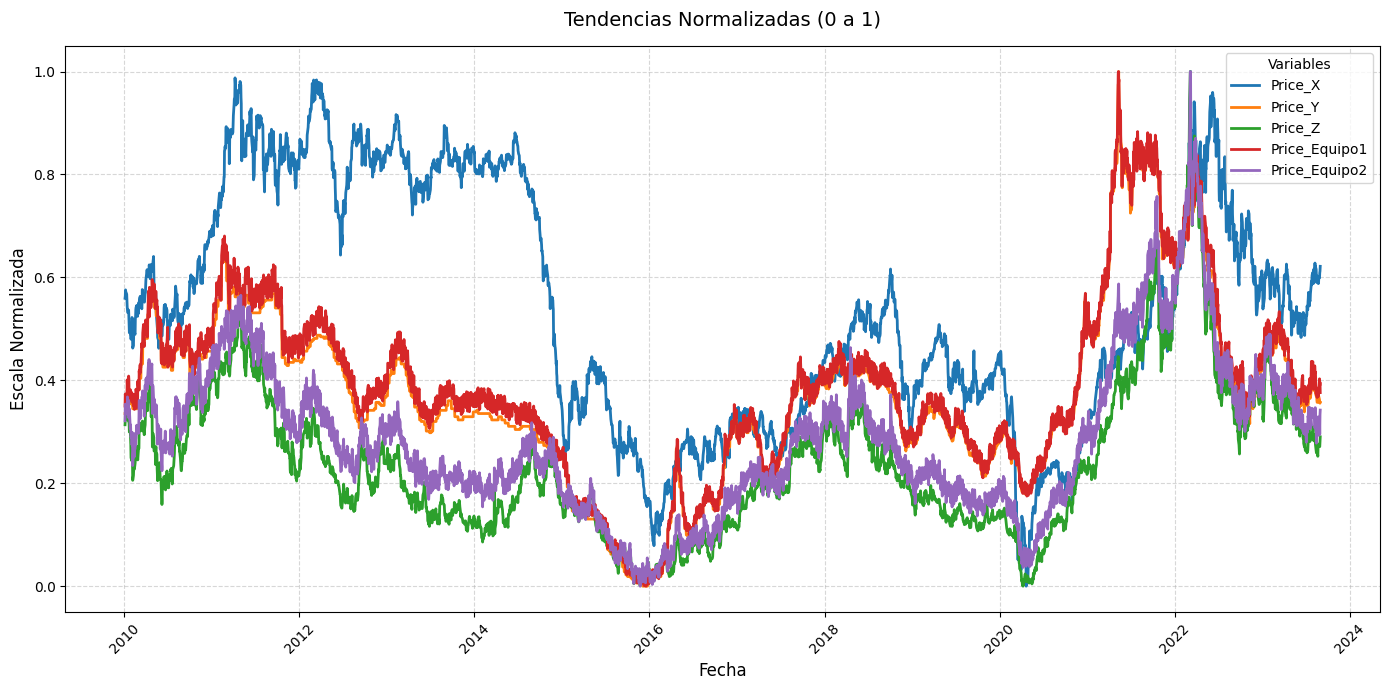

In [13]:
df_norm = (df - df.min()) / (df.max() - df.min())

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_norm, dashes=False, linewidth=2, palette='tab10')

plt.title('Tendencias Normalizadas (0 a 1)', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Escala Normalizada', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Variables')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

Se vuelve a mostrar las gráficas pero ahora estan normalizadas donde podemos observar de nuevo las tendercias en las variables ya mencionadas.

### Matriz de correlación de Pearson

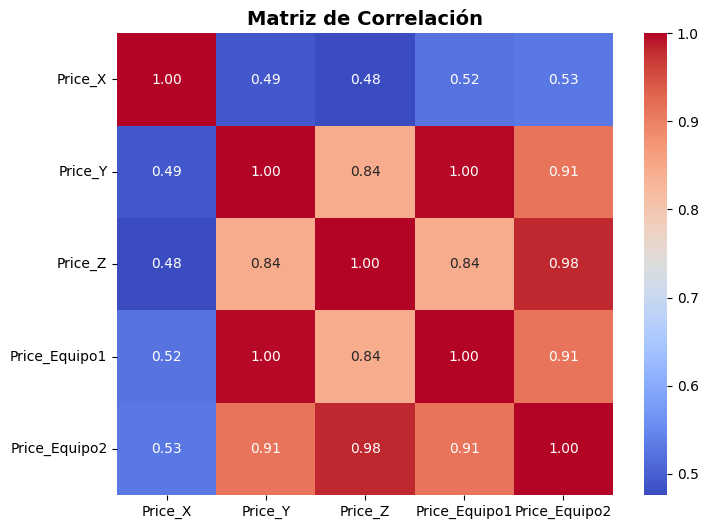

In [14]:
plt.figure(figsize=(8, 6)) # Tamaño del gráfico
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt=".2f")

plt.title("Matriz de Correlación", fontsize=14, fontweight='bold')
plt.show()

En el análisis de la matriz de correlación encontramos un hallazgo crítico: existe una correlación perfecta (1.0) entre Price_Y y Price_Equipo1, y una correlación casi perfecta (0.98) entre Price_Z y Price_Equipo2.

Esto sugiere una relación determinista, donde el precio de los equipos está dictado casi exclusivamente por estas materias primas específicas. La variable Price_X, al no mostrar correlación, no parece ser un insumo directo para estos equipos en particular.

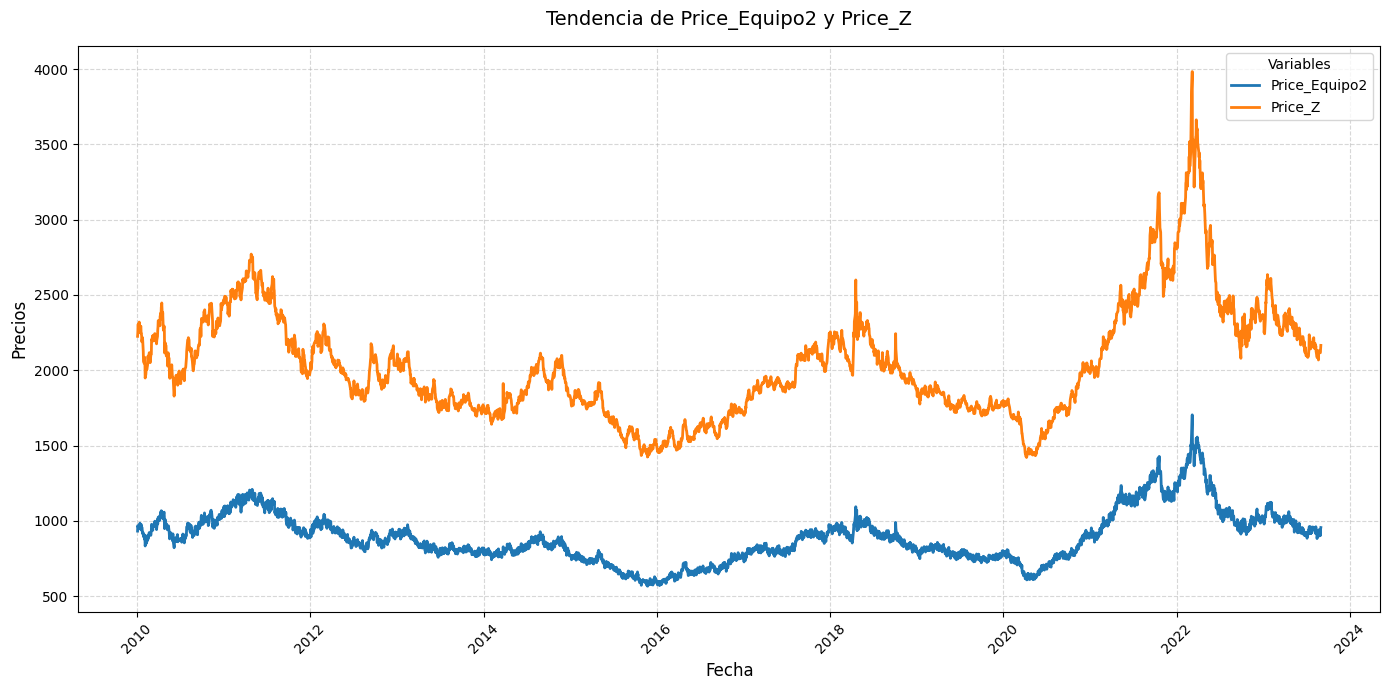

In [15]:
df_corr2= df[['Price_Equipo2','Price_Z']]

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_corr2, dashes=False, linewidth=2, palette='tab10')

plt.title('Tendencia de Price_Equipo2 y Price_Z', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precios', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Variables')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



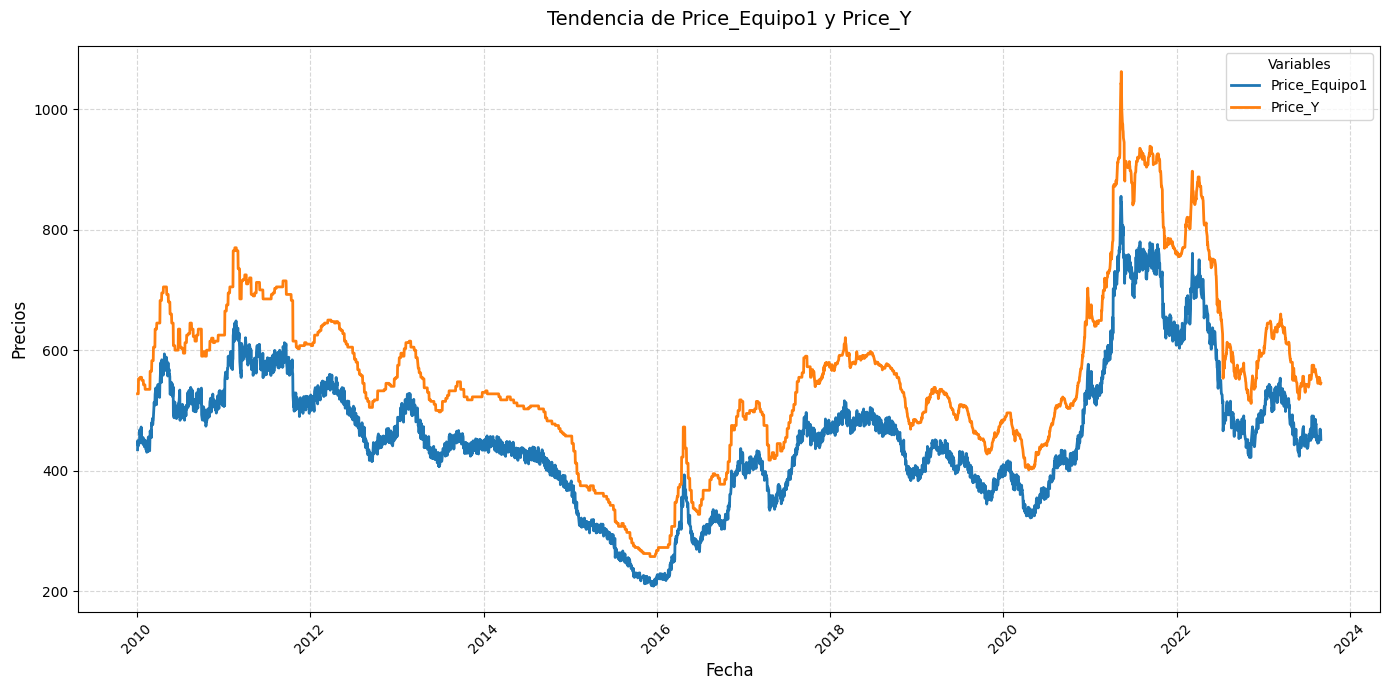

In [16]:
df_corr1= df[['Price_Equipo1','Price_Y']]

plt.figure(figsize=(14, 7))
sns.lineplot(data=df_corr1, dashes=False, linewidth=2, palette='tab10')

plt.title('Tendencia de Price_Equipo1 y Price_Y', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precios', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Variables')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Comprobación de los resultados anteriores usando regresión lineal de Seaborn

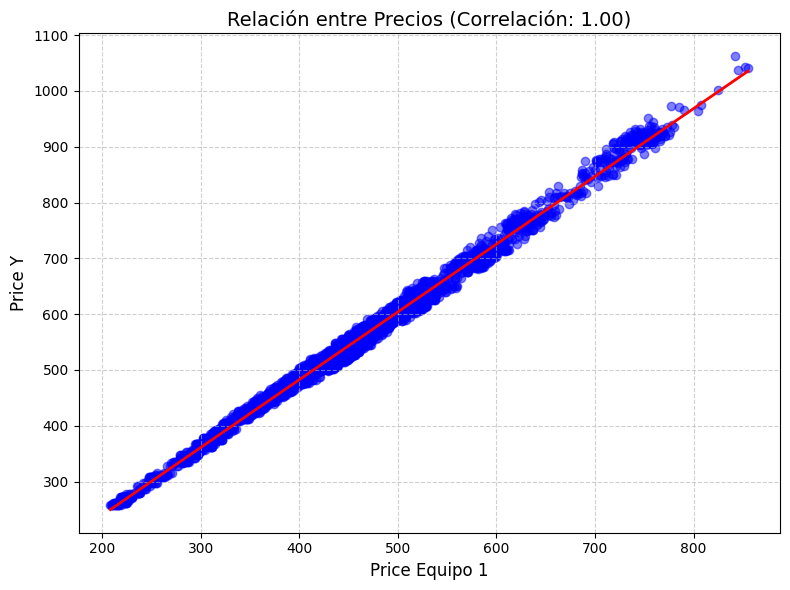

In [17]:
plt.figure(figsize=(8, 6))
sns.regplot(data=df, x='Price_Equipo1', y='Price_Y', 
            scatter_kws={'alpha':0.5, 'color':'blue'},
            line_kws={'color':'red', 'linewidth':2})   
corr_val = df['Price_Equipo1'].corr(df['Price_Y'])
plt.title(f'Relación entre Precios (Correlación: {corr_val:.2f})', fontsize=14)
plt.xlabel('Price Equipo 1', fontsize=12)
plt.ylabel('Price Y', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

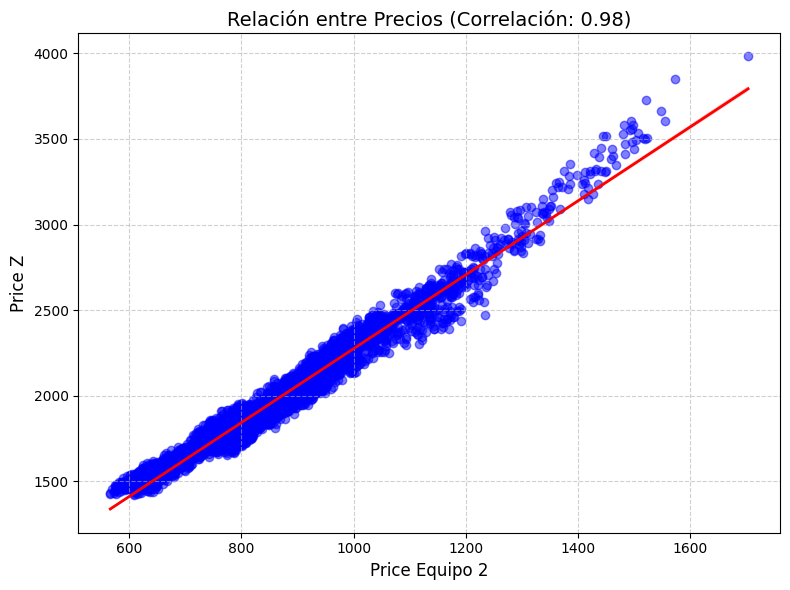

In [18]:
plt.figure(figsize=(8, 6))

sns.regplot(data=df, x='Price_Equipo2', y='Price_Z', 
            scatter_kws={'alpha':0.5, 'color':'blue'},
            line_kws={'color':'red', 'linewidth':2})   
corr_val = df['Price_Equipo2'].corr(df['Price_Z'])
plt.title(f'Relación entre Precios (Correlación: {corr_val:.2f})', fontsize=14)
plt.xlabel('Price Equipo 2', fontsize=12)
plt.ylabel('Price Z', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Para no depender únicamente de los coeficientes de la matriz de correlación, validé estos hallazgos mediante gráficos de dispersión (scatter plots) ajustados con una línea de regresión lineal simple.

Se encontraron los siguientes hallazgos:
En Price_Y vs Price_Equipo1, el gráfico muestra una línea recta perfecta, confirmando una relación determinista (R² ≈ 1.0). No se observan outliers ni ruido. En Price_Z vs Price_Equipo2, el ajuste lineal es casi perfecto (R² ≈ 0.98), con una dispersión mínima alrededor de la línea de tendencia.
La visualización de la dispersión confirma que la relación entre las materias primas y los equipos es estrictamente lineal y determinista.

### Interfaz gráfica e interactica de las gráficas

In [19]:
dropdown_equipo = widgets.Dropdown(
    options=['Price_X','Price_Y','Price_Z','Price_Equipo1', 'Price_Equipo2'],
    value='Price_Equipo2',
    description='Variable:',
)

# Función que se ejecuta al cambiar el valor
def actualizar_grafica(variable):
    plt.figure(figsize=(10, 5))
    plt.plot(df.index, df[variable], color='purple', linewidth=2)
    plt.title(f'Evolución de {variable}')
    plt.grid(True, alpha=0.5)
    plt.show()

widgets.interact(actualizar_grafica, variable=dropdown_equipo)

interactive(children=(Dropdown(description='Variable:', index=4, options=('Price_X', 'Price_Y', 'Price_Z', 'Pr…

<function __main__.actualizar_grafica(variable)>

## Conclusión

El análisis confirma que el precio de los equipos está dictado casi exclusivamente por materias primas específicas: Price_Equipo1 depende totalmente de Price_Y (correlación de 1.0) y Price_Equipo2 de Price_Z (0.98). Por el contrario, Price_X no muestra ninguna relación útil con los equipos.

Al ser una relación lineal y determinista, no tiene sentido usar modelos complejos como XGBoost o Random Forest(al menos para correlación) . Opté por una regresión lineal múltiple con Seaborn porque es más rápida, 100% interpretable.

In [20]:
df_X.head()

,Price
Date,
2024-04-04,89.18
2024-04-03,89.35
2024-04-02,88.92
2024-04-01,87.42
2024-03-28,87.48


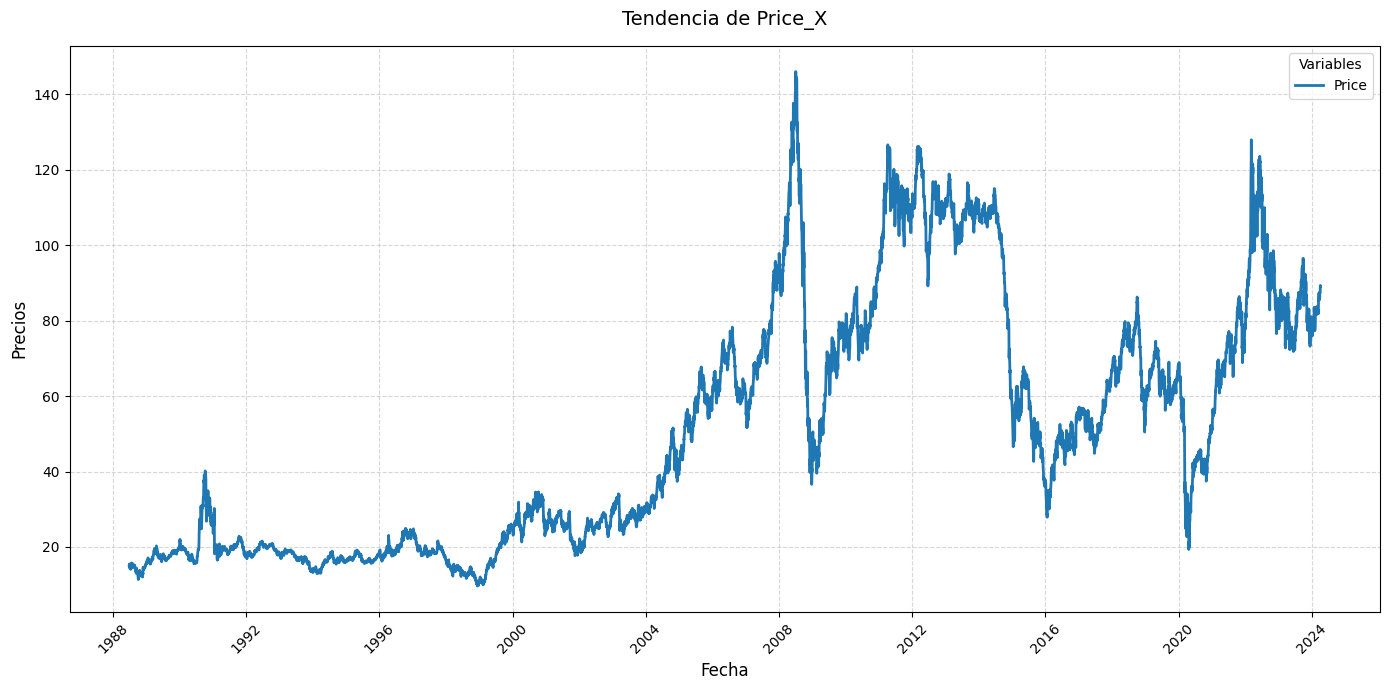

In [21]:
plt.figure(figsize=(14, 7))
sns.lineplot(data=df_X, dashes=False, linewidth=2, palette='tab10')

plt.title('Tendencia de Price_X', fontsize=14, pad=15)
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precios', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Variables')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

En esta parte se busca comprobar que los datos históricos del CSV de X, coincida con los datos datos_historicos_equipos, aunque recordemos de los análisis anteriores, Price_X no impacta en los equipos.

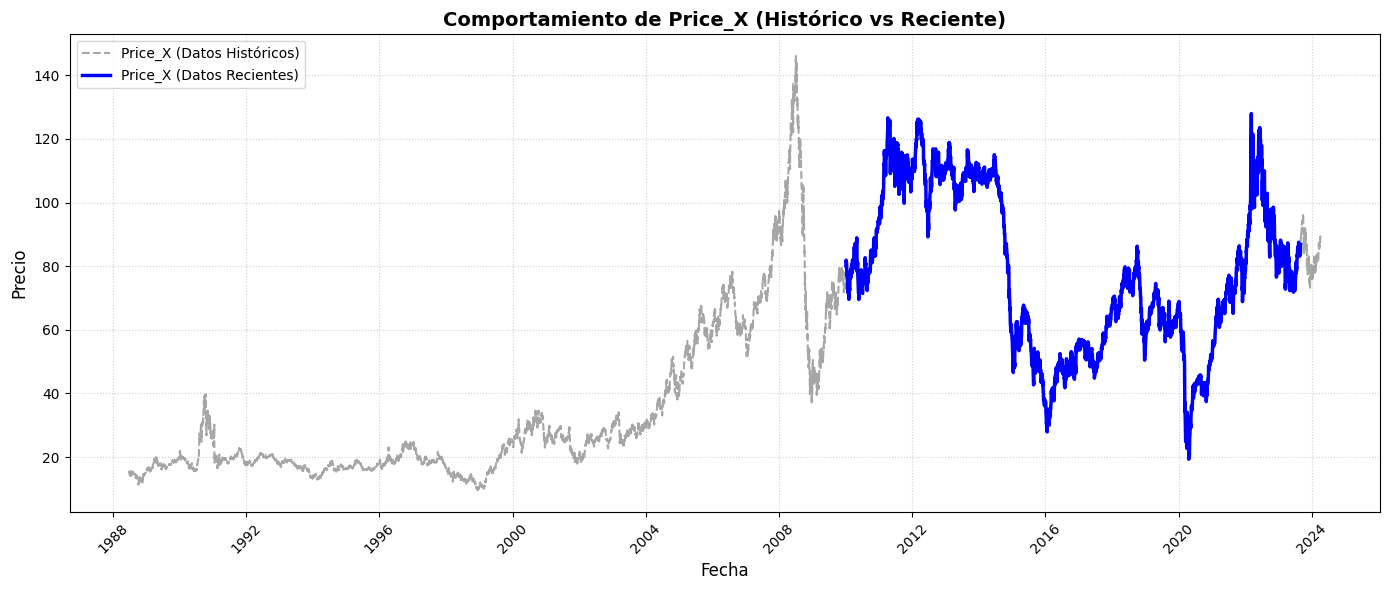

In [22]:
df_X.index = pd.to_datetime(df_X.index)
df.index = pd.to_datetime(df.index)

plt.figure(figsize=(14, 6))


plt.plot(df_X.index, df_X['Price'], 
         color='gray', linestyle='--', linewidth=1.5, alpha=0.7, 
         label='Price_X (Datos Históricos)')

plt.plot(df.index, df['Price_X'], 
         color='b', linewidth=2.5, 
         label='Price_X (Datos Recientes)')

plt.title('Comportamiento de Price_X (Histórico vs Reciente)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precio', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
df_Y.head(10)

,Date;Price
12/9/2023;547,33.0
11/9/2023;546,NaN
8/9/2023;545,NaN
7/9/2023;550,NaN
6/9/2023;552,5.0
5/9/2023;553,33.0
4/9/2023;553,33.0
1/9/2023;551,58.0
31/8/2023;545,NaN
30/8/2023;543,67.0


Se hizo la revisión del CSV Y y se encontraron varias incosistencias, principalmente con el formato de las fechas y los precios, se trato de hacer una separación usando el ";" pero no funciono, queda pendiente a revisión.

In [24]:
df_Z.head() #Este tenía un indice distinto y se abordo dede el inicio

,Price
Date,
2010-01-01,2225.25
2010-01-04,2225.25
2010-01-05,2246.50
2010-01-06,2302.50
2010-01-07,2306.50


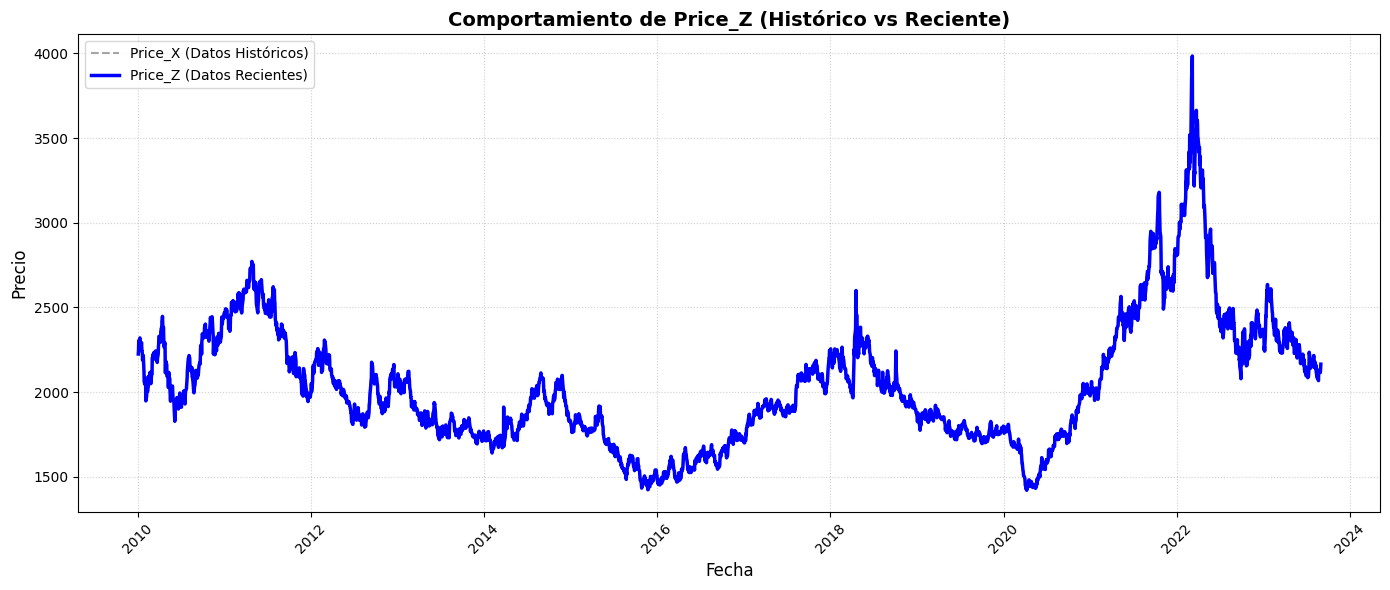

In [25]:
df_Z.index = pd.to_datetime(df_Z.index)
df.index = pd.to_datetime(df.index)

plt.figure(figsize=(14, 6))


plt.plot(df_Z.index, df_Z['Price'], 
         color='gray', linestyle='--', linewidth=1.5, alpha=0.7, 
         label='Price_X (Datos Históricos)')

plt.plot(df.index, df['Price_Z'], 
         color='b', linewidth=2.5, 
         label='Price_Z (Datos Recientes)')

plt.title('Comportamiento de Price_Z (Histórico vs Reciente)', fontsize=14, fontweight='bold')
plt.xlabel('Fecha', fontsize=12)
plt.ylabel('Precio', fontsize=12)
plt.legend(loc='upper left', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Aquí tenemos que los datos son consistentes.